### the dataset used here is realword collected from cdac khrghar sector 3 , with the help of dht22 sensor and esp32 with firebase 

In [1]:
import pandas as pd 


In [3]:
ds=pd.read_csv('DHT22_Dataset.csv')

In [4]:
ds.head()

,record_id,humidity,status,temperature,timestamp
0,-P5IFbPjVBBKnoXF4LIa,78.3,True,32.4,1793471968000
1,-P5IFbuXNOwMuNxskJxE,78.3,True,32.4,1793471970000
2,-P5IFcPo9iXCVoKarjnr,78.3,True,32.4,1793471972000
3,-P5IFcv3NY37CUogbb0P,78.3,True,32.4,1793471974000
4,-P5IFdM6GPXfNtlyrV-R,78.3,True,32.4,1793471976000


In [5]:
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 45357 entries, 0 to 45356
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   record_id    45357 non-null  str    
 1   humidity     45270 non-null  float64
 2   status       45357 non-null  bool   
 3   temperature  45270 non-null  float64
 4   timestamp    45357 non-null  int64  
dtypes: bool(1), float64(2), int64(1), str(1)
memory usage: 1.4 MB


In [6]:
#there is no missing value 
ds.isnull().sum()

record_id       0
humidity       87
status          0
temperature    87
timestamp       0
dtype: int64

In [7]:
from datetime import datetime

ds['date_time']=pd.to_datetime(ds['Timestamp'],unit='ms',utc=True).dt.tz_convert('Asia/Kolkata')

ds['Date'] = ds['date_time'].dt.strftime('%Y-%m-%d')
ds['Time'] = ds['date_time'].dt.strftime('%H:%M:%S')

KeyError: 'Timestamp'

In [25]:
ds.head(100)

,Timestamp,Temperature_C,Humidity_pct,date_time,Date,Time
0,1793471968000,32.4,78.3,2026-11-01 00:09:28+05:30,2026-11-01,00:09:28
1,1793471970000,32.4,78.3,2026-11-01 00:09:30+05:30,2026-11-01,00:09:30
2,1793471972000,32.4,78.3,2026-11-01 00:09:32+05:30,2026-11-01,00:09:32
3,1793471974000,32.4,78.3,2026-11-01 00:09:34+05:30,2026-11-01,00:09:34
4,1793471976000,32.4,78.3,2026-11-01 00:09:36+05:30,2026-11-01,00:09:36
...,...,...,...,...,...,...
95,1793472224000,32.4,78.1,2026-11-01 00:13:44+05:30,2026-11-01,00:13:44
96,1793472226000,32.4,78.1,2026-11-01 00:13:46+05:30,2026-11-01,00:13:46
97,1793472228000,32.4,78.1,2026-11-01 00:13:48+05:30,2026-11-01,00:13:48
98,1793472230000,32.4,78.1,2026-11-01 00:13:50+05:30,2026-11-01,00:13:50


In [26]:
ds=ds.drop(columns=['Timestamp','date_time'])

In [27]:
ds

,Temperature_C,Humidity_pct,Date,Time
0,32.4,78.3,2026-11-01,00:09:28
1,32.4,78.3,2026-11-01,00:09:30
2,32.4,78.3,2026-11-01,00:09:32
3,32.4,78.3,2026-11-01,00:09:34
4,32.4,78.3,2026-11-01,00:09:36
...,...,...,...,...
45265,30.6,73.3,2026-11-02,02:22:33
45266,30.6,73.4,2026-11-02,02:22:35
45267,30.6,73.4,2026-11-02,02:22:37
45268,30.6,73.4,2026-11-02,02:22:39


In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

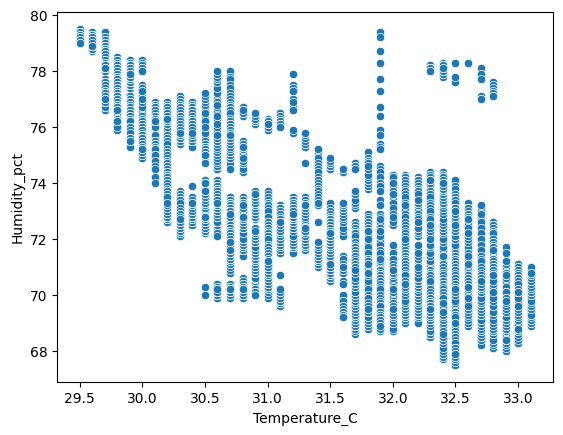

In [29]:
sns.scatterplot(data=ds, x="Temperature_C", y="Humidity_pct")
plt.show()

In [ ]:
#sns.lineplot(data=ds, x="Time", y="Humidity_pct")
#plt.show()

KeyboardInterrupt: 

In [32]:
ds.to_csv('clean_HT.csv', index=False)   